## Analyze spontaneous data

Analyses spontaneous swimming data across all fish.

Import libraries:

In [1]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import SPEED_SEGMENTED_DIR, media_dir
path = str(SPEED_SEGMENTED_DIR)
path_media = str(media_dir(path))

%load_ext autoreload
%autoreload 2
from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
from functions.brain_analysis import *
from functions.utilities import *
from functions.feedback_models import *
from functions.freely_swimming import *

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd

In [1]:
# path, path_media set in first cell

In [3]:
# path_media created in first cell

#### Import data:

In [4]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']

In [5]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']

In [6]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']

In [7]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [8]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

In [9]:
len(fish_ids)

22

Load:

In [10]:
speed_clean = pd.read_hdf(os.path.join(path, f"speed_clean.h5"), key='df')

In [11]:
speed_clean

,ID,t_c,vfish_c,vtail_c,dangletail_c,angletail_c,freqtail_c,mean_thrust_c
0,13_06May24_1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1,13_06May24_1,0.003333,NaN,NaN,NaN,NaN,NaN,NaN
2,13_06May24_1,0.006667,NaN,NaN,NaN,NaN,NaN,NaN
3,13_06May24_1,0.010000,NaN,NaN,NaN,NaN,NaN,NaN
4,13_06May24_1,0.013333,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
21727813,34_11Dec24_3,320.736667,NaN,NaN,NaN,NaN,NaN,NaN
21727814,34_11Dec24_3,320.740000,NaN,NaN,NaN,NaN,NaN,NaN
21727815,34_11Dec24_3,320.743333,NaN,NaN,NaN,NaN,NaN,NaN
21727816,34_11Dec24_3,320.746667,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
thrust_thresholds = pd.read_hdf(os.path.join(path, f"thrust_thresholds.h5"), key='df')

In [13]:
thrust_thresholds

,ID,thrust_thr,mask_movetail
0,13_06May24_1,0.000331,False
1,13_06May24_1,0.000331,False
2,13_06May24_1,0.000331,False
3,13_06May24_1,0.000331,False
4,13_06May24_1,0.000331,False
...,...,...,...
21727813,34_11Dec24_3,0.025991,False
21727814,34_11Dec24_3,0.025991,False
21727815,34_11Dec24_3,0.025991,False
21727816,34_11Dec24_3,0.025991,False


In [14]:
onsets = pd.read_hdf(os.path.join(path, f"onsets.h5"), key='df')

In [15]:
onsets

,ID,onset_indices,initial_vfish,initial_vtail,bout_duration
0,13_06May24_1,1369,6.717492,102.127655,2.566667
1,13_06May24_1,2987,4.772649,90.986139,1.966667
2,13_06May24_1,4877,7.283671,136.008985,1.780000
3,13_06May24_1,5695,6.163918,100.164392,2.900000
4,13_06May24_1,6601,3.750249,69.222574,0.966667
...,...,...,...,...,...
45480,34_11Dec24_3,92811,24.794113,263.748909,0.213333
45481,34_11Dec24_3,92984,35.093076,348.691133,0.213333
45482,34_11Dec24_3,93206,38.267398,332.921438,0.196667
45483,34_11Dec24_3,93407,35.724430,275.439541,0.216667


In [16]:
t_c_list=[]
vfish_c_list=[]
vtail_c_list=[]
mean_thrust_c_list=[]
angletail_c_list=[]
dangletail_c_list=[]
freqtail_c_list=[]

for fish_ID in tqdm(fish_ids):
    speed_clean_fish=subset_by_fish(fish_ID,DF1=speed_clean)[0]
    t_c_list.append(speed_clean_fish['t_c'].values)
    vfish_c_list.append(speed_clean_fish['vfish_c'].values)
    vtail_c_list.append(speed_clean_fish['vtail_c'].values)    
    mean_thrust_c_list.append(speed_clean_fish['mean_thrust_c'].values)
    angletail_c_list.append(speed_clean_fish['angletail_c'].values)
    dangletail_c_list.append(speed_clean_fish['dangletail_c'].values)
    freqtail_c_list.append(speed_clean_fish['freqtail_c'].values)

  0%|                                                    | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|██                                          | 1/22 [00:06<02:14,  6.42s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|████                                        | 2/22 [00:11<01:53,  5.65s/it]

...

 91%|███████████████████████████████████████    | 20/22 [01:42<00:09,  4.83s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████████████████████████████████████  | 21/22 [01:47<00:04,  4.80s/it]

Subsetting data of the fish 34_11Dec24_3


100%|███████████████████████████████████████████| 22/22 [01:52<00:00,  5.10s/it]


In [17]:
thrust_thr_list=[]
mask_movetail_list=[]

for fish_ID in tqdm(fish_ids):
    thrust_thresholds_fish=subset_by_fish(fish_ID,DF1=thrust_thresholds)[0]
    thrust_thr_list.append(thrust_thresholds_fish['thrust_thr'].values[0])
    mask_movetail_list.append(thrust_thresholds_fish['mask_movetail'].values)

  0%|                                                    | 0/22 [00:00<?, ?it/s]

Subsetting data of the fish 13_06May24_1


  5%|██                                          | 1/22 [00:05<01:45,  5.04s/it]

Subsetting data of the fish 13_30Oct24_3


  9%|████                                        | 2/22 [00:09<01:35,  4.77s/it]

...

 91%|███████████████████████████████████████    | 20/22 [01:35<00:09,  4.71s/it]

Subsetting data of the fish 34_11Dec24_1


 95%|█████████████████████████████████████████  | 21/22 [01:39<00:04,  4.68s/it]

Subsetting data of the fish 34_11Dec24_3


100%|███████████████████████████████████████████| 22/22 [01:44<00:00,  4.75s/it]


In [18]:
onset_indices_list=[]
initial_vfish_list=[]
initial_vtail_list=[]
bout_duration_list=[]

for fish_ID in tqdm(fish_ids):
    onsets_fish=subset_by_fish(fish_ID,DF1=onsets)[0]
    onset_indices_list.append(onsets_fish['onset_indices'].values)
    initial_vfish_list.append(onsets_fish['initial_vfish'].values)
    initial_vtail_list.append(onsets_fish['initial_vtail'].values)
    bout_duration_list.append(onsets_fish['bout_duration'].values)

 45%|███████████████████▌                       | 10/22 [00:00<00:00, 89.80it/s]

Subsetting data of the fish 13_06May24_1
Subsetting data of the fish 13_30Oct24_3
Subsetting data of the fish 13_30Oct24_4
Subsetting data of the fish 14_27Mar24_1
Subsetting data of the fish 14_31Oct24_1
Subsetting data of the fish 17_21May24_2
Subsetting data of the fish 18_22May24_1
Subsetting data of the fish 18_22May24_2
Subsetting data of the fish 19_23May24_5
Subsetting data of the fish 20_05Jun24_1
Subsetting data of the fish 20_05Jun24_2
Subsetting data of the fish 20_12Jun24_1
Subsetting data of the fish 21_06Dec24_1
Subsetting data of the fish 21_06Dec24_2
Subsetting data of the fish 21_06Jun24_1
Subsetting data of the fish 25_10Jun24_1
Subsetting data of the fish 26_02May24_2
Subsetting data of the fish 27_12Jun24_1
Subsetting data of the fish 28_04May24_1
Subsetting data of the fish 30_06May24_2


100%|███████████████████████████████████████████| 22/22 [00:00<00:00, 90.63it/s]

Subsetting data of the fish 34_11Dec24_1
Subsetting data of the fish 34_11Dec24_3


In [19]:
@interact(i=(0,len(mean_thrust_c_list)-1,1))
def plot(i=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.hist(np.log10(mean_thrust_c_list[i]),bins=100,histtype='step',density=True)
    ax.axvline(np.log10(thrust_thr_list[i]),c='k')
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=21), Output()), _dom_classes=('widget-interact',…

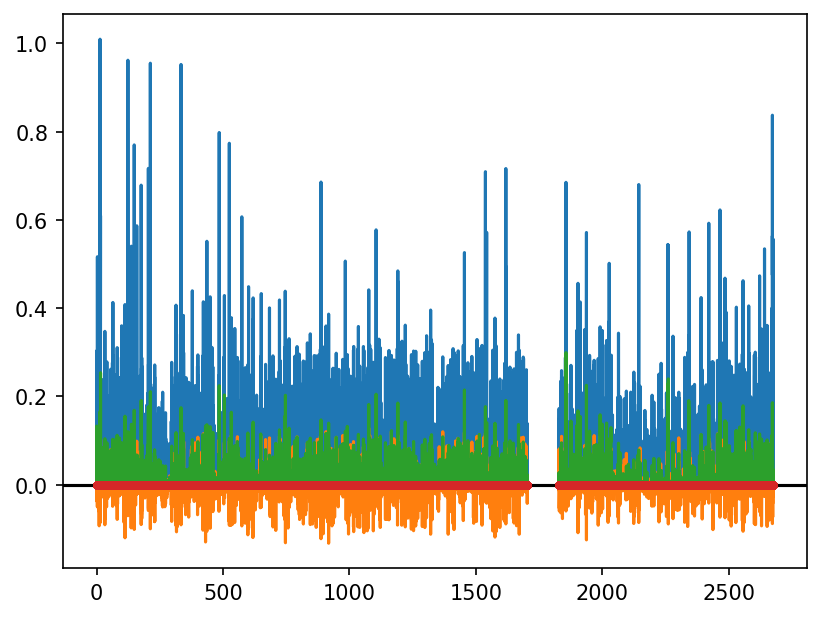

In [22]:
i=13
dt=1/300
default()
inline()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.plot(t_c_list[i],vtail_c_list[i]/1000,'-')
ax.plot(t_c_list[i],angletail_c_list[i]/10,'-')
ax.plot(t_c_list[i],mean_thrust_c_list[i],'-')
ax.axhline(thrust_thr_list[i],c='k')
ax.plot(t_c_list[i][mask_movetail_list[i]], np.zeros(np.sum(mask_movetail_list[i])),'.')

plt.show()

In [23]:
i=10
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],c='k')
    ax.set_xlim(-t_before,t_after)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=1101), Output()), _dom_classes=('widget-interact…

In [24]:
i=10
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,vfish_c_list[i][indices]/1000,'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices]/10000,'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,mean_thrust_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],c='k')
    ax.axhline(thrust_thr_list[i],c='k')
    ax.set_xlim(-t_before,t_after)
    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=1101), Output()), _dom_classes=('widget-interact…

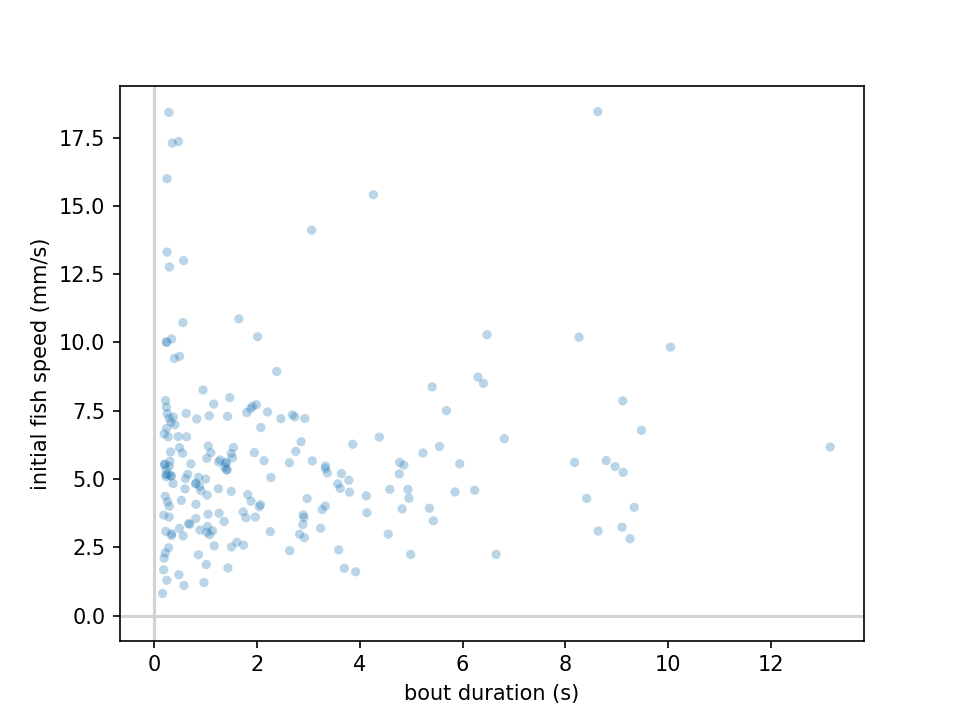

In [25]:
i=1
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.axhline(0,c='lightgray')
ax.axvline(0,c='lightgray')
ax.scatter(bout_duration_list[i],initial_vfish_list[i],s=20,alpha=0.3,edgecolor='none')

ax.set_xlabel('bout duration (s)')
ax.set_ylabel('initial fish speed (mm/s)')

plt.show()

#### Distributions:

In [26]:
i=15

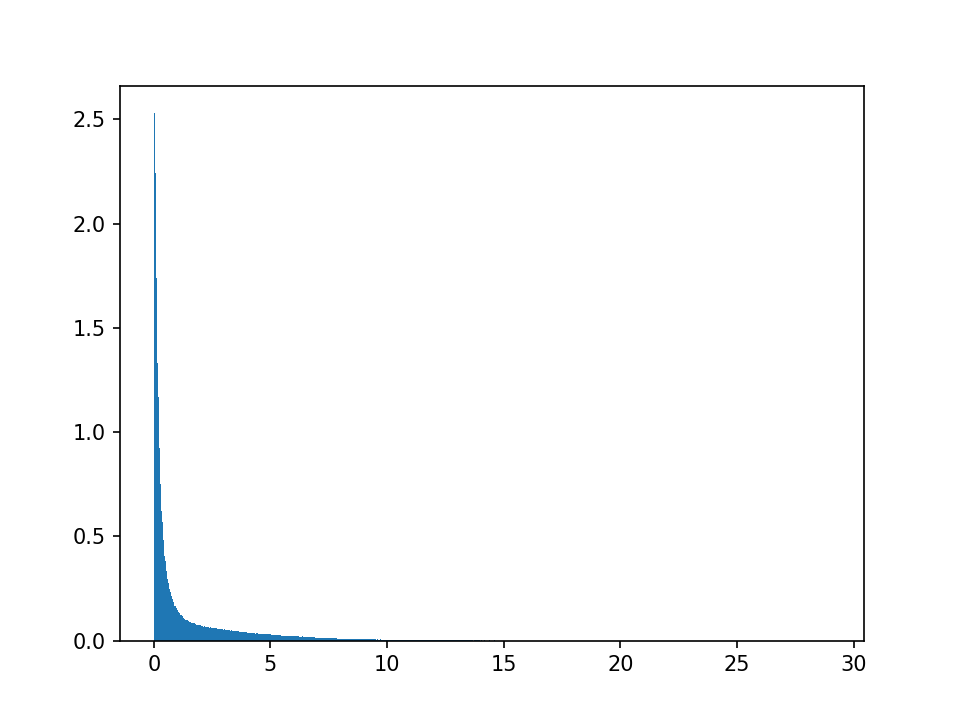

In [27]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(vfish_c_list[i],bins='auto',density=True)
plt.show()

In [28]:
np.nanmedian(vfish_c_list[i])

np.float64(0.383637297157572)

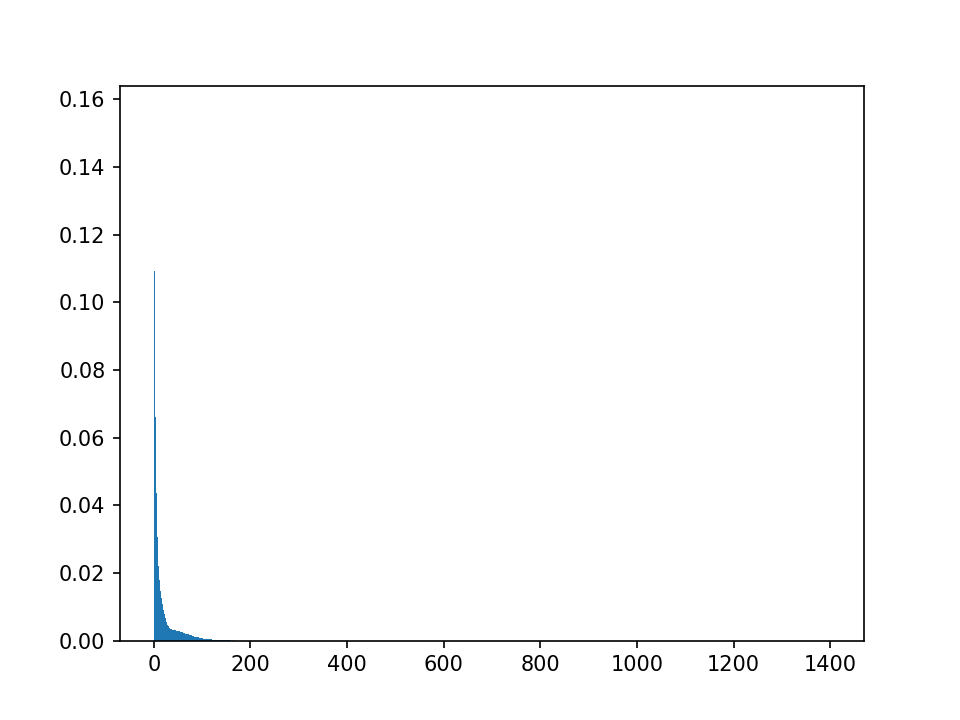

In [29]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(vtail_c_list[i],bins='auto',density=True)
plt.show()

In [30]:
np.nanmedian(vtail_c_list[i])

np.float64(6.041602842487761)

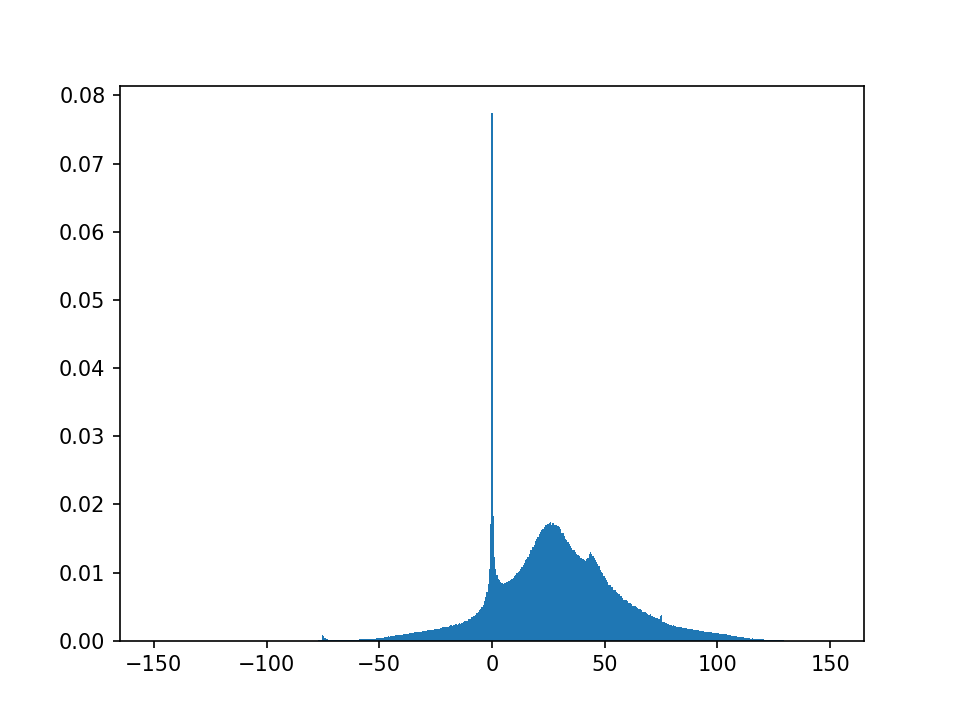

In [31]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(freqtail_c_list[i],bins='auto',density=True)
plt.show()

In [32]:
np.nanmedian(freqtail_c_list[i])

np.float64(27.212208133336212)

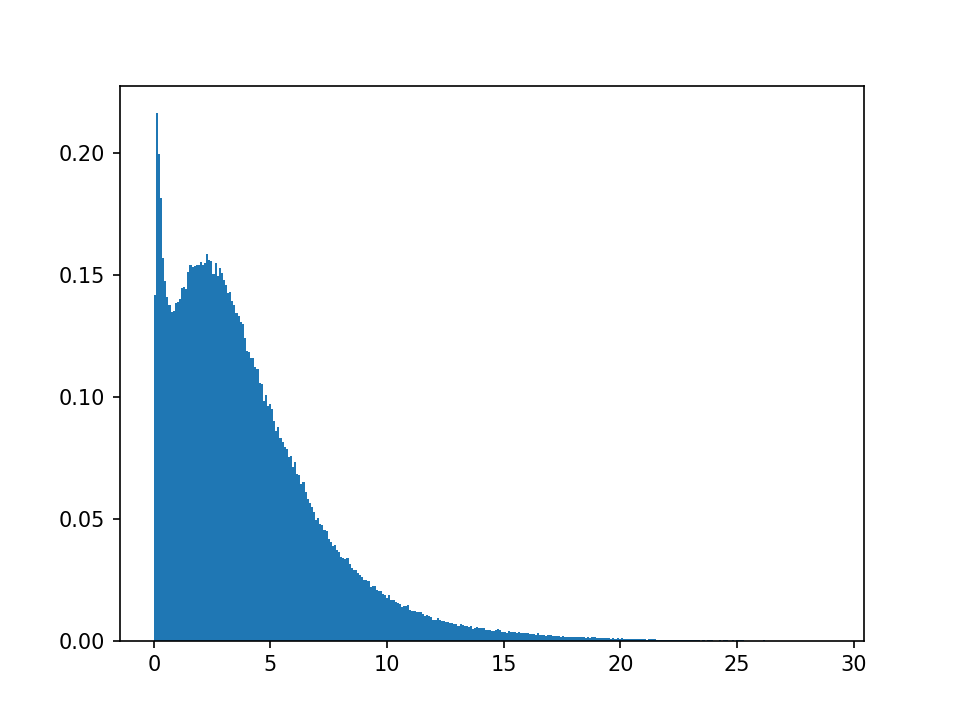

In [33]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(vfish_c_list[i][mask_movetail_list[i]],bins='auto',density=True)
plt.show()

In [34]:
np.nanmedian(vfish_c_list[i][mask_movetail_list[i]])

np.float64(3.2759040531900405)

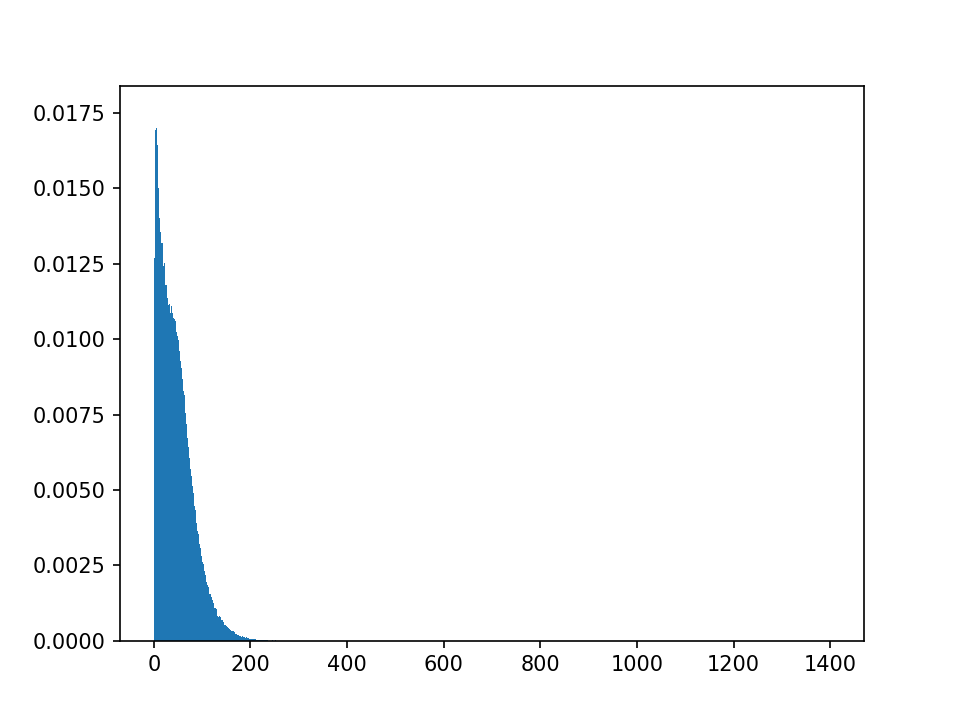

In [35]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(vtail_c_list[i][mask_movetail_list[i]],bins='auto',density=True)
plt.show()

In [36]:
np.nanmedian(vtail_c_list[i][mask_movetail_list[i]])

np.float64(38.89147184788184)

In [37]:
mask_activeperiods=compute_mask_without_long_quiescence(mean_thrust_c_list[i],mask_movetail_list[i])

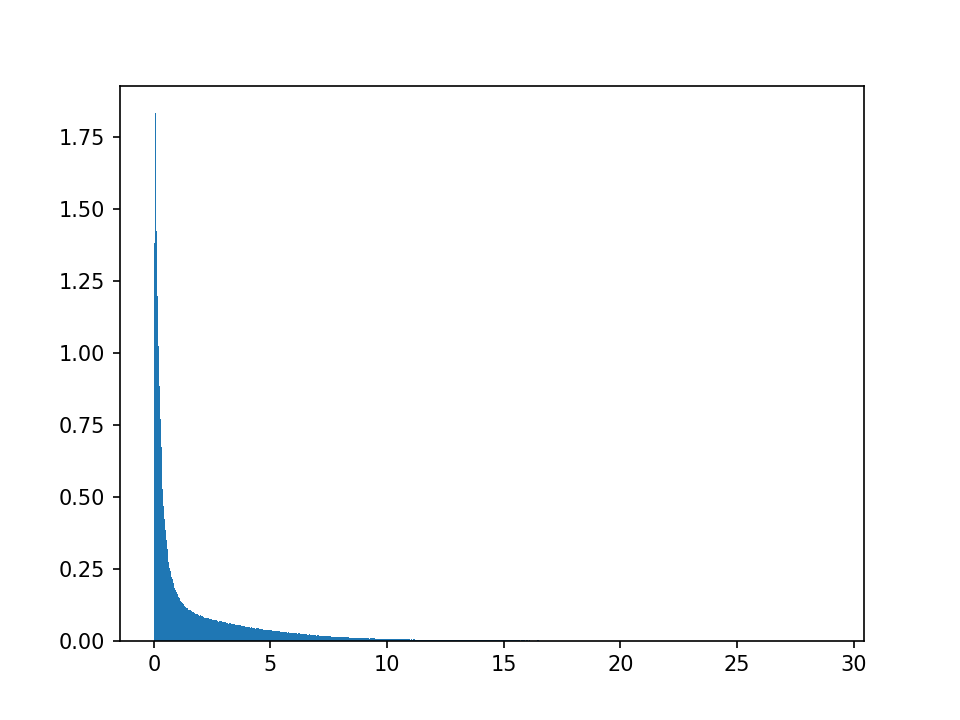

In [38]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(vfish_c_list[i][mask_activeperiods],bins='auto',density=True)
plt.show()

In [39]:
np.nanmedian(vfish_c_list[i][mask_activeperiods])

np.float64(0.5513641478311391)

#### Find transformation tail speed to fish speed:

In [40]:
i=13

In [41]:
vfish_sequences=find_consecutive_sequences_mask(vfish_c_list[i],~np.isnan(vfish_c_list[i]))
vtail_sequences=find_consecutive_sequences_mask(vtail_c_list[i],~np.isnan(vtail_c_list[i]))
len_sequences=np.array([len(vfish_seq) for vfish_seq in vfish_sequences])

In [42]:
best_lmbds,best_taus=get_delay_and_factor_from_exponential_convolution(vfish_sequences,vtail_sequences)

100%|███████████████████████████████████████████| 46/46 [00:06<00:00,  6.76it/s]


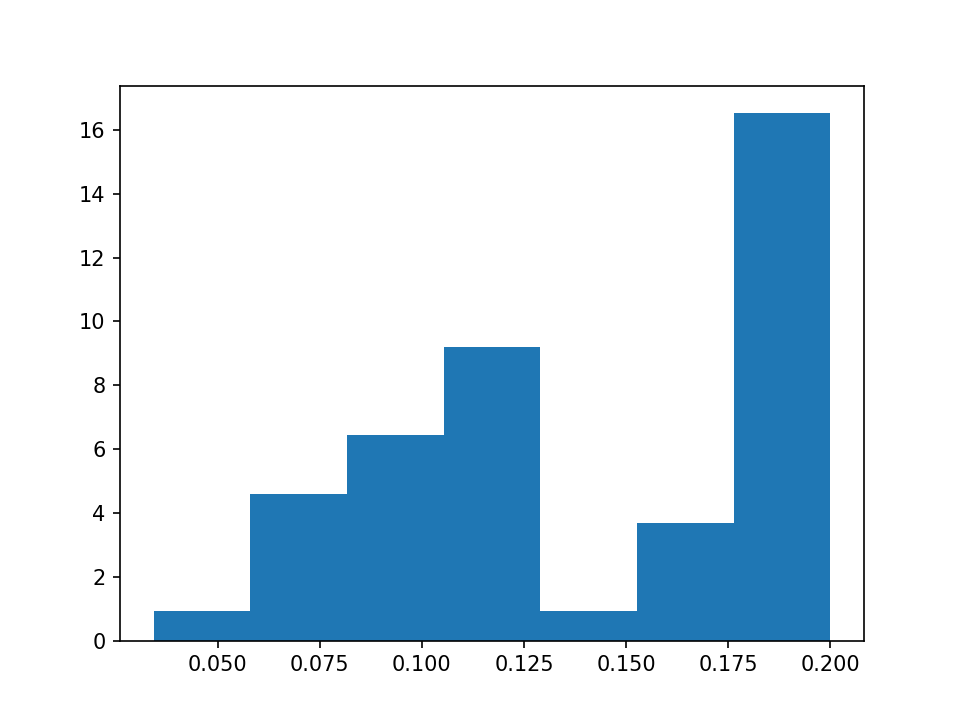

In [43]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(best_taus,bins='auto',density=True)
plt.show()

In [44]:
np.median(best_taus)

np.float64(0.13737373737373737)

In [45]:
np.mean(best_taus)

np.float64(0.14317083882301276)

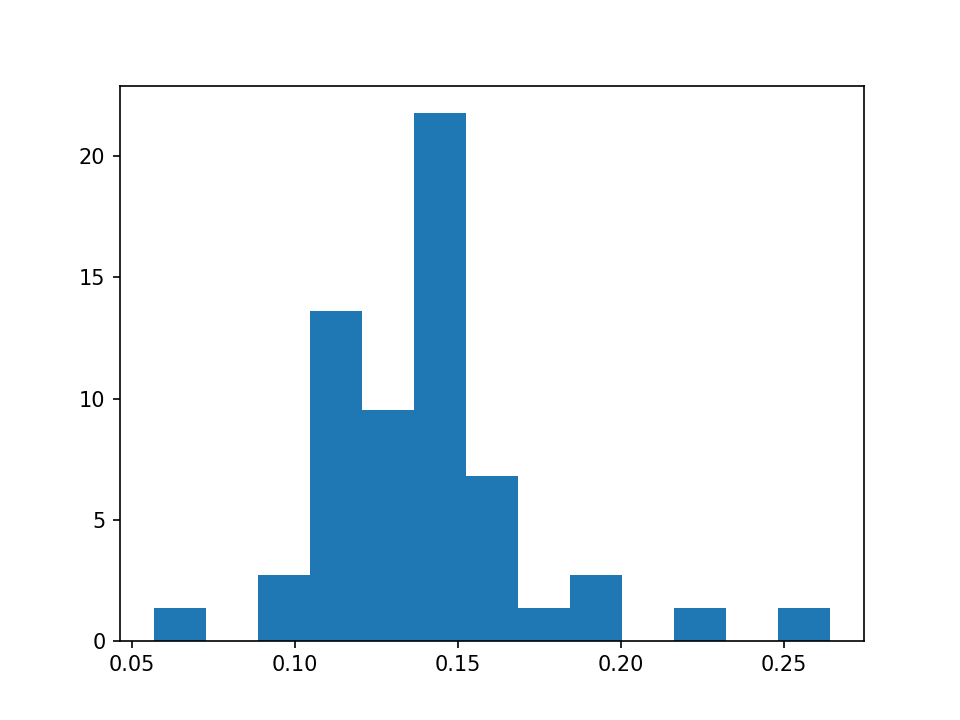

In [46]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(best_lmbds,bins='auto',density=True)
plt.show()

In [47]:
np.median(best_lmbds)

np.float64(0.13800236727156015)

In [48]:
np.mean(best_lmbds)

np.float64(0.13934105072240835)

In [49]:
best_sts=1/(2*best_lmbds)

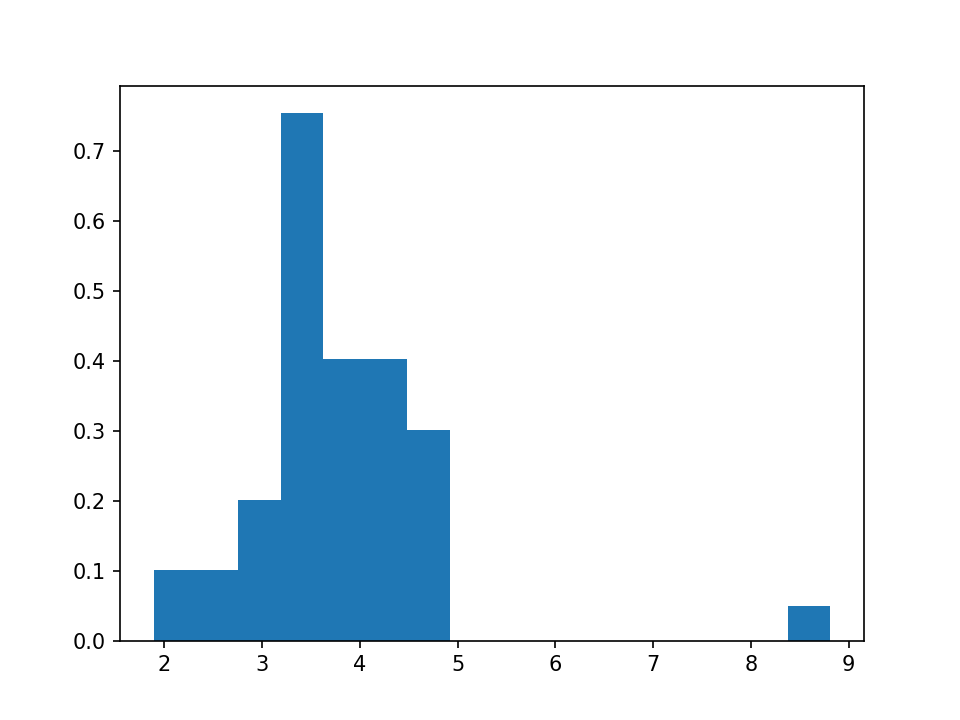

In [50]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.hist(best_sts,bins='auto',density=True)
plt.show()

In [51]:
np.median(best_sts)

np.float64(3.6231327725329807)

In [52]:
np.mean(best_sts)

np.float64(3.7867763189198658)

#### Plot sequences:

In [53]:
dt=1/300
@interact(i=(0,len(vtail_sequences)-1,1))
def plot(i=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_seq=dt*np.arange(len_sequences[i])
    ax.plot(t_seq,vfish_sequences[i],'.-',alpha=0.6)
    ax.plot(t_seq,best_lmbds[i]*np.array(vtail_sequences[i]),'.-',alpha=0.6)
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=45), Output()), _dom_classes=('widget-interact',…

#### Onset traces:

In [54]:
i=15

In [55]:
dt=1/300
t_before=0.1
t_after=1
@interact(n=(0,len(onset_indices_list[i])-1,1))
def plot(n=0):
    default()
    widget()
    fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
    ax.axhline(0,color='lightgray')
    ax.axvline(0,color='lightgray')
    t_onset=t_c_list[i][onset_indices_list[i][n]]
    indices=(t_c_list[i]>t_onset-t_before)&(t_c_list[i]<t_onset+t_after)
    ax.plot(t_c_list[i][indices]-t_onset,10*vfish_c_list[i][indices],'.-',alpha=0.6)
    ax.plot(t_c_list[i][indices]-t_onset,vtail_c_list[i][indices],'.-',alpha=0.6)
    ax.axvline(bout_duration_list[i][n],color='gray')
    ax.set_xlim(-t_before,t_after)

    plt.show()

interactive(children=(IntSlider(value=0, description='n', max=3452), Output()), _dom_classes=('widget-interact…

In [56]:
dt=1/300
t_before=0.1
t_after=1

i_before=round(t_before/dt)
i_after=round(t_after/dt)


vfish_c_onsets=np.full((len(onset_indices_list[i]),i_before+i_after),np.nan)

for n in range(len(onset_indices_list[i])):

    vfish_c_onsets[n]=np.copy(vfish_c_list[i][onset_indices_list[i][n]-i_before:onset_indices_list[i][n]+i_after])

    vfish_c_onsets[n,:i_before]=0

    if bout_duration_list[i][n]<t_after:
        vfish_c_onsets[n,i_before+round(bout_duration_list[i][n]/dt):]=0
    

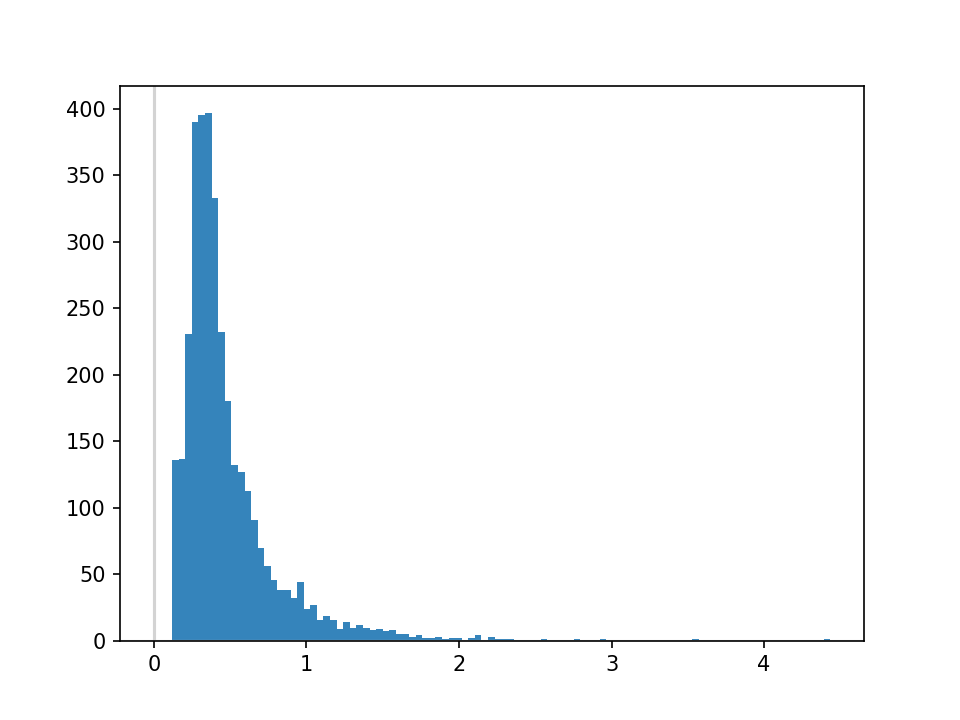

In [57]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')
ax.hist(bout_duration_list[i],bins=100,alpha=0.9)

    
plt.show()

In [58]:
vfish_c_onsets_m=np.nanquantile(vfish_c_onsets,0.5,axis=0)
vfish_c_onsets_iqp=np.nanquantile(vfish_c_onsets,0.75,axis=0)-np.nanquantile(vfish_c_onsets,0.5,axis=0)
vfish_c_onsets_iqm=np.nanquantile(vfish_c_onsets,0.5,axis=0)-np.nanquantile(vfish_c_onsets,0.25,axis=0)

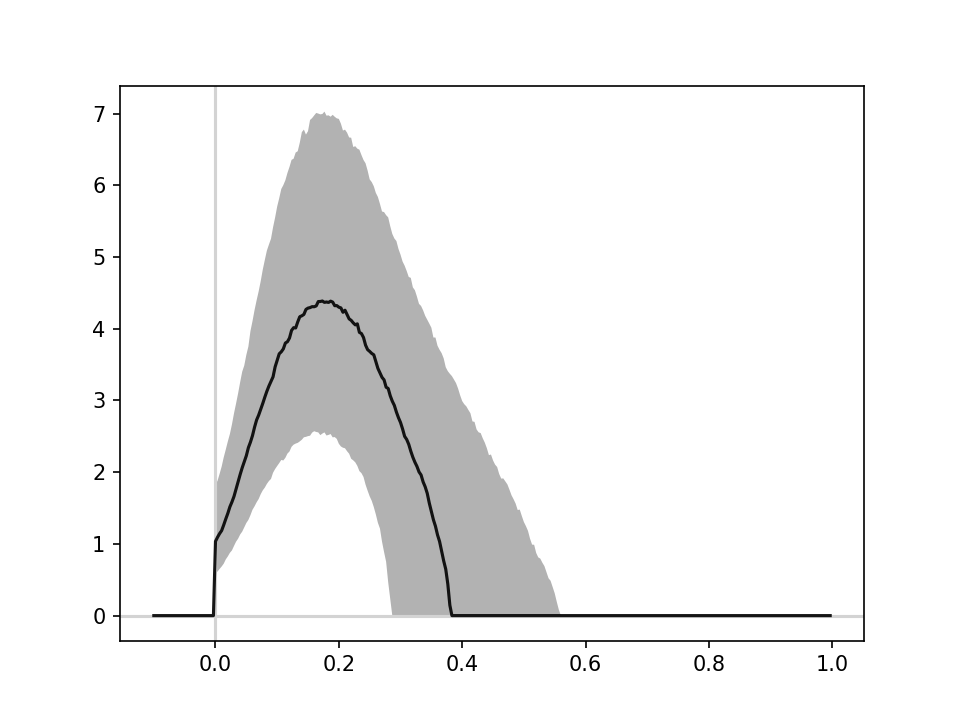

In [59]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')
ax.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_m,'k-',alpha=0.9)
ax.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_m-vfish_c_onsets_iqm,vfish_c_onsets_m+vfish_c_onsets_iqp,color='k',alpha=0.3,ec=None)

    
plt.show()

In [60]:
dur_thr=0.8
vfish_c_onsets_int=vfish_c_onsets[np.array(bout_duration_list[i])<dur_thr]
vfish_c_onsets_m_int=np.nanquantile(vfish_c_onsets_int,0.5,axis=0)
vfish_c_onsets_iqp_int=np.nanquantile(vfish_c_onsets_int,0.75,axis=0)-np.nanquantile(vfish_c_onsets_int,0.5,axis=0)
vfish_c_onsets_iqm_int=np.nanquantile(vfish_c_onsets_int,0.5,axis=0)-np.nanquantile(vfish_c_onsets_int,0.25,axis=0)

vfish_c_onsets_cont=vfish_c_onsets[np.array(bout_duration_list[i])>dur_thr]
vfish_c_onsets_m_cont=np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)
vfish_c_onsets_iqp_cont=np.nanquantile(vfish_c_onsets_cont,0.75,axis=0)-np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)
vfish_c_onsets_iqm_cont=np.nanquantile(vfish_c_onsets_cont,0.5,axis=0)-np.nanquantile(vfish_c_onsets_cont,0.25,axis=0)

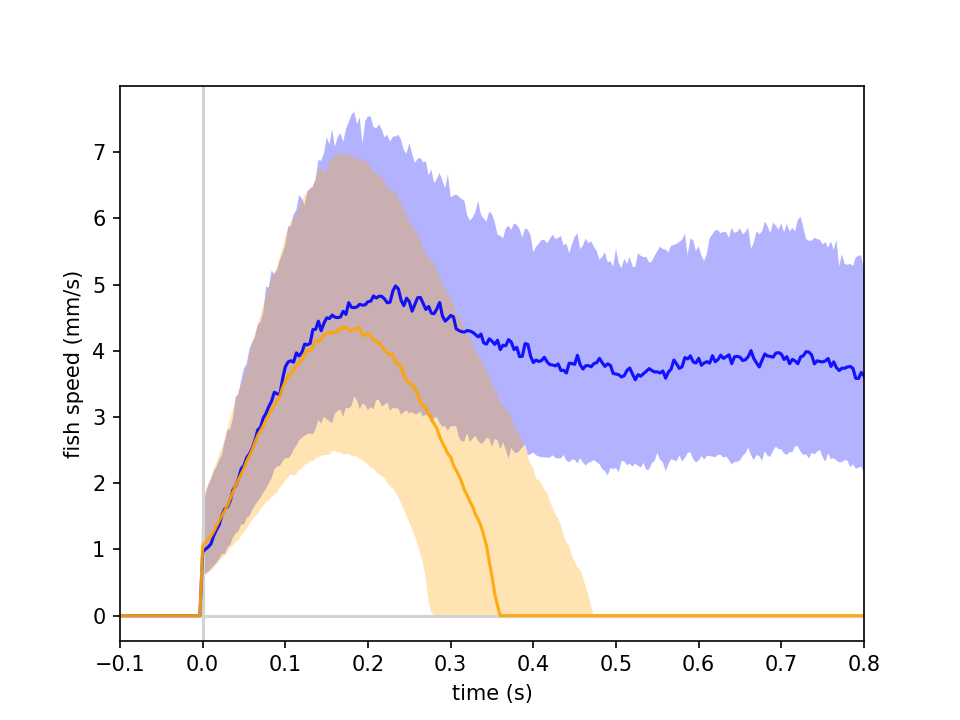

In [61]:
default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=150)
ax.axhline(0,color='lightgray')
ax.axvline(0,color='lightgray')

c_cont='b'
c_int='orange'

ax.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_m_cont,c=c_cont,alpha=0.9)
ax.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_m_cont-vfish_c_onsets_iqm_cont,vfish_c_onsets_m_cont+vfish_c_onsets_iqp_cont,color=c_cont,alpha=0.3,ec=None)

ax.plot(dt*np.arange(-i_before,i_after),vfish_c_onsets_m_int,c=c_int,alpha=0.9)
ax.fill_between(dt*np.arange(-i_before,i_after),vfish_c_onsets_m_int-vfish_c_onsets_iqm_int,vfish_c_onsets_m_int+vfish_c_onsets_iqp_int,color=c_int,alpha=0.3,ec=None)

ax.set_xlim(-t_before,dur_thr)


ax.set_xlabel('time (s)')
ax.set_ylabel('fish speed (mm/s)')

plt.show()